# Tennessee Eastman Process (TEP)

Simulated chemical plant benchmark (Downs & Vogel, 1993; re-simulated by Rieth et al. 2017) widely used for fault detection and change-point detection research. Each testing run is fault-free for the first 160 samples (3 min/sample), after which one of 20 faults is injected for the remainder of the run.

**Protocol** (see [`tep_sweep.py`](tep_sweep.py), the single source of truth for the pipeline used here): the detection threshold is calibrated on 100 held-out fault-free testing runs -- no fault-onset information is used -- then applied unchanged to all 20 faults x 500 runs of the faulty testing set. This notebook loads the cached sweep results (re-run `python tep_sweep.py` to regenerate) and demonstrates the pipeline on one example run. Baseline methods will be added for comparison later.


In [ ]:
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_curve

sys.path.append("../")

import tep_sweep as sweep

from reshift.datasets import load_tep
from reshift.plot import plot_chd

In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
# [donotremove]
RESULTS_PATH = Path("results/.tep/tep_sweep.pkl")
if not RESULTS_PATH.exists():
    sweep.main()

with RESULTS_PATH.open("rb") as f:
    results = pickle.load(f)  # noqa: S301  trusted local pickle
records = results["records"]

print(
    f"threshold={results['threshold']:.5f} ({results['params']['calib_quantile']:.1%} quantile over {results['n_calib_runs']} held-out fault-free runs)",
)
print(
    f"FAR: {results['far_sample_rate']:.3%} of samples, {results['far_run_rate']:.1%} of {results['n_holdout_runs']} held-out fault-free runs raised >=1 alarm",
)

threshold=0.00842 (99.9% quantile over 100 held-out fault-free runs)
FAR: 0.142% of samples, 17.2% of 400 held-out fault-free runs raised >=1 alarm


## ROC AUC -- threshold-free discriminability

Miss rate / delay below hinge on the single calibrated threshold, a real but somewhat arbitrary operating point. AUC asks a threshold-independent question instead: across *every* threshold, does the score rank faulty samples above normal ones? It's also the metric future baseline methods should be compared on, since their raw scores won't share this scale.

**A labeling pitfall to avoid**: AUC needs a genuine "normal" class. Using a faulty run's own pre-onset samples as that class only works if the detector was actually scoring during that window -- if the model's warm-up (`GRACE_PERIOD`) runs past the fault onset, those "pre-onset" scores are trivially 0.0 (scoring hasn't started), not genuine evidence of normal operation, and AUC against them is meaningless. `tep_sweep.py` asserts `GRACE_PERIOD < FAULT_ONSET` to guard against this, and AUC here is computed per fault against real, independently-scored held-out fault-free samples -- never a faulty run's own pre-onset window.


In [ ]:
clean_auc = pd.Series(results["clean_auc_per_fault"]).sort_index()
clean_auc.index.name = "fault"
print(f"Overall mean AUC (20 faults): {clean_auc.mean():.3f}")

In [ ]:
summary = records.groupby("fault").agg(
    miss_rate=("detected", lambda s: 1 - s.mean()),
    mean_delay=("delay", "mean"),
)
summary["auc"] = clean_auc
summary = summary[["auc", "miss_rate", "mean_delay"]].round(3)

print(
    f"Overall miss rate: {1 - records['detected'].mean():.1%} across {len(records)} (fault, run) pairs",
)
print(
    f"Overall mean detection delay (detected runs only): "
    f"{records.loc[records['detected'], 'delay'].mean():.1f} samples",
)
summary

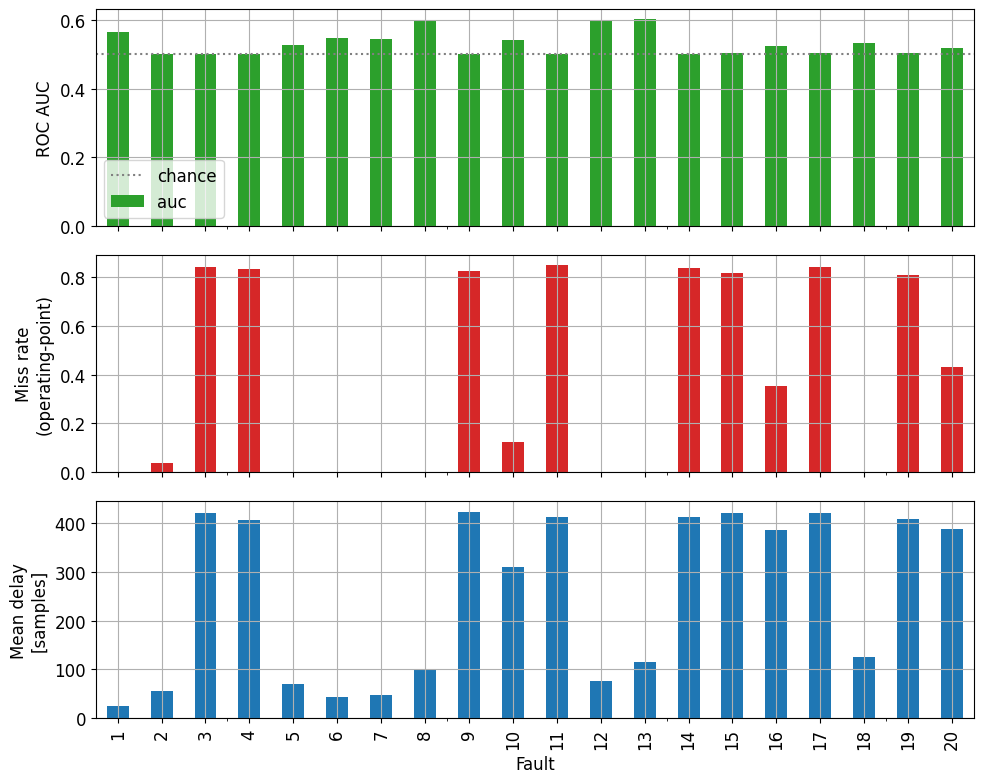

In [ ]:
# [donotremove]
_fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
summary["auc"].plot.bar(ax=axs[0], color="tab:green")
axs[0].set_ylabel("ROC AUC")
axs[0].axhline(0.5, color="grey", ls=":", label="chance")
axs[0].legend()
summary["miss_rate"].plot.bar(ax=axs[1], color="tab:red")
axs[1].set_ylabel("Miss rate\n(operating-point)")
summary["mean_delay"].plot.bar(ax=axs[2], color="tab:blue")
axs[2].set_ylabel("Mean delay\n[samples]")
axs[2].set_xlabel("Fault")
_fig.tight_layout()

## Comparison to published literature

We reproduce the protocol of [Heo & Lee 2019](https://doi.org/10.3390/pr7070411) (*Processes* 7(7):411), an unsupervised PCA/autoencoder-residual study on this same Rieth et al. dataset: sample-level fault detection rate (fraction of post-onset samples flagged) at a controlled false-alarm rate of 1%, averaged over the 17 faults excluding 3/9/15 -- which every published study (including this one) finds essentially undetectable by any method, so including them would penalize every method identically and add noise rather than signal.

Rather than compare at that single operating point alone, we also plot our full ROC curve (pooled over the same 17 faults, against the same clean held-out negatives used for AUC above) and mark where their reported point falls on it -- the direct answer to "would a different threshold close the gap?"


In [ ]:
LIT_EXCLUDE_FAULTS = {3, 9, 15}

print(
    f"Realized FAR at the FAR=1% operating point: "
    f"{results['lit_far_sample_rate']:.3%} of held-out fault-free samples",
)

lit_subset = records[~records["fault"].isin(LIT_EXCLUDE_FAULTS)]
print(
    f"Our sample-level FDR @ FAR=1%, 17-fault subset: "
    f"{lit_subset['sample_fdr'].mean():.3f} "
    f"(+/- {lit_subset['sample_fdr'].std():.3f})",
)
print("Heo & Lee 2019 (best method, same protocol, same 17 faults): 0.72-0.77")

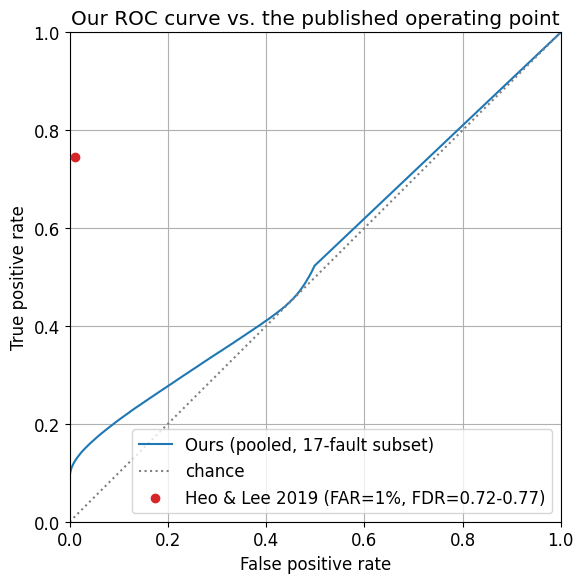

In [ ]:
# [donotremove]
grace_period = results["params"]["grace_period"]
fault_onset = results["params"]["fault_onset"]

neg = np.concatenate(
    [s[grace_period:] for s in results["holdout_scores"].values()],
)
pos = np.concatenate(
    [
        s[fault_onset - 1 :]
        for (fault, _run), s in results["faulty_scores"].items()
        if fault not in LIT_EXCLUDE_FAULTS
    ],
)
y = np.concatenate([np.zeros(len(neg)), np.ones(len(pos))])
fpr, tpr, _thr = roc_curve(y, np.concatenate([neg, pos]))

_fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, label="Ours (pooled, 17-fault subset)")
ax.plot([0, 1], [0, 1], color="grey", ls=":", label="chance")
ax.scatter(
    [0.01],
    [0.745],
    color="tab:red",
    zorder=5,
    label="Heo & Lee 2019 (FAR=1%, FDR=0.72-0.77)",
)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(loc="lower right")
ax.set_title("Our ROC curve vs. the published operating point")
_fig.tight_layout()

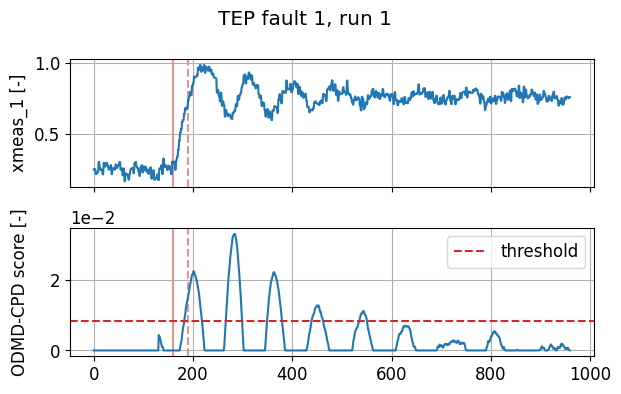

In [ ]:
# [donotremove]
# Example run: fault 1, simulation run 1 -- same fixed, pre-calibrated
# threshold as the sweep above (no leakage from this run's own onset).
FAULT_NUMBER, SIMULATION_RUN = 1, 1

X = load_tep(sweep.TEP_PATH, FAULT_NUMBER, SIMULATION_RUN)
scores = pd.Series(sweep.score_run(X), index=X.index)
alarms = scores > results["threshold"]

fig, axs = plot_chd(
    {
        "xmeas_1 [-]": X["xmeas_1"].to_numpy(),
        "ODMD-CPD score [-]": scores.to_numpy(),
    },
    y_true=[sweep.FAULT_ONSET - 1],
    grace_period=30,
)
axs[1].axhline(
    results["threshold"],
    color="tab:red",
    ls="--",
    label="threshold",
)
axs[1].legend()
fig.suptitle(f"TEP fault {FAULT_NUMBER}, run {SIMULATION_RUN}")
fig.tight_layout()